# Projeto Solar V3 — previsão horária de geração fotovoltaica
**Machine Learning | LSTM com restrições físicas**

Versão autônoma para Jupyter e Colab, baseada nos arquivos `solar.py`, `physics.py`, `testar.py` e `graficos.py` da V3. Execute todas as células em ordem. Horizonte de uma hora, com histórico de 24 horas e meteorologia da hora-alvo.

**Atenção:** a base padrão contém 120 dias fictícios de uma instalação hipotética em Recife-PE. Não comprova precisão em instalações reais. A física é simplificada, sem uso da biblioteca PVlib.

## 1. Dependências
Se faltar alguma biblioteca, retire o comentário da linha de instalação.

In [ ]:
# %pip install numpy pandas scikit-learn torch joblib matplotlib

In [ ]:
import copy, json
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from IPython.display import display
print('PyTorch:', torch.__version__)

PyTorch: 2.14.1+cpu


## 2. Configuração dos equipamentos
Parâmetros da instalação hipotética: 10 placas de 550 Wp, inversor de 5 kW. Azimute 0° = norte. Os parâmetros adicionais são hipóteses. Para repetir o benchmark V3, mantenha 40 épocas e três sementes. Para teste rápido, use 2 épocas e uma semente; as métricas serão diferentes.

In [ ]:
CONFIG = {'nome': 'Instalação-exemplo Recife (não real)',
 'cidade': 'Recife, Pernambuco',
 'latitude': -8.05,
 'longitude': -34.88,
 'tipo_sistema': 'on_grid',
 'quantidade_placas': 10,
 'potencia_placa_wp': 550,
 'inversor_kw': 5.0,
 'inclinacao_graus': 10,
 'orientacao': 'norte',
 'tem_bateria': False,
 'tem_gerador_auxiliar': False,
 'eficiencia_inversor': 0.96,
 'coeficiente_termico': -0.0035,
 'noct_c': 45,
 'perdas_dc': 0.08,
 'azimute_graus': 0,
 'albedo': 0.2}
MODO = 'demo'  # 'demo' ou 'csv'
CSV = 'geracao_medida.csv'
MODO_CLIMA = 'previsao'  # 'previsao' ou 'historico' para CSV
EPOCAS = 40
SEMENTES = [42, 123, 2026]
SAIDA = Path('resultados_v3_notebook')
SAIDA.mkdir(parents=True, exist_ok=True)
assert EPOCAS >= 1 and SEMENTES and len(set(SEMENTES)) == len(SEMENTES)
c = CONFIG
if not (c['quantidade_placas']>0 and c['potencia_placa_wp']>0 and c['inversor_kw']>0 and 0<c['eficiencia_inversor']<=1 and 0<=c['perdas_dc']<1 and 0<=c['inclinacao_graus']<=90 and 0<=c['azimute_graus']<360 and -0.02<=c['coeficiente_termico']<=0 and c['noct_c']>20 and 0<=c['albedo']<=1):
    raise ValueError('Configuração inválida')
assert c['tipo_sistema']=='on_grid' and not c['tem_bateria'] and not c['tem_gerador_auxiliar']
print('Potência DC:', c['quantidade_placas']*c['potencia_placa_wp']/1000, 'kWp')
print('Inversor:', c['inversor_kw'], 'kW')

Potência DC: 5.5 kWp
Inversor: 5.0 kW


## 3. Modelagem física
Calcula posição solar, irradiância no plano dos módulos, temperatura da célula, perdas DC, eficiência AC e limite do inversor. Cada registro é energia em kWh durante uma hora.

In [ ]:
def vector(idx,c):
    h=idx.hour.to_numpy()+idx.minute.to_numpy()/60
    g=2*np.pi/365*(idx.dayofyear.to_numpy()-1+(h-12)/24)
    eq=229.18*(.000075+.001868*np.cos(g)-.032077*np.sin(g)-.014615*np.cos(2*g)-.040849*np.sin(2*g))
    dec=.006918-.399912*np.cos(g)+.070257*np.sin(g)-.006758*np.cos(2*g)+.000907*np.sin(2*g)-.002697*np.cos(3*g)+.00148*np.sin(3*g)
    ha=np.deg2rad((h*60+eq+4*c['longitude']+180)/4-180); lat=np.deg2rad(c['latitude'])
    return np.sin(lat)*np.sin(dec)+np.cos(lat)*np.cos(dec)*np.cos(ha), np.cos(lat)*np.sin(dec)-np.sin(lat)*np.cos(dec)*np.cos(ha), -np.cos(dec)*np.sin(ha)

def reference(d,c):
    v=np.array([vector(d.index-pd.Timedelta(minutes=m),c) for m in (5,15,25,35,45,55)])
    up,north,east=v.transpose(1,0,2); lit=up>0; day=lit.any(0)
    b=np.deg2rad(c['inclinacao_graus']); az=np.deg2rad(c['azimute_graus'])
    cos_aoi=(np.maximum(up*np.cos(b)+np.sin(b)*(north*np.cos(az)+east*np.sin(az)),0)*lit).sum(0)/np.maximum(lit.sum(0),1)
    ghi,dni,dhi=[np.maximum(d[k].to_numpy(float),0) for k in ['shortwave_radiation','direct_normal_irradiance','diffuse_radiation']]
    poa=np.where(day,dni*cos_aoi+dhi*(1+np.cos(b))/2+ghi*c['albedo']*(1-np.cos(b))/2,0)
    cell=d.temperature_2m.to_numpy(float)+(c['noct_c']-20)*poa/800/(1+.1*np.maximum(d.wind_speed_10m.to_numpy(float)/3.6-1,0))
    kwp=c['quantidade_placas']*c['potencia_placa_wp']/1000
    dc=np.maximum(0,kwp*poa/1000*(1+c['coeficiente_termico']*(cell-25))*(1-c['perdas_dc']))
    ac=np.minimum(dc*c['eficiencia_inversor'],c['inversor_kw'])
    return pd.DataFrame(dict(poa_wm2=poa,temp_celula_c=cell,potencia_dc_kw=dc,referencia_kwh=ac,diurno=day),index=d.index)

## 4. Gerador de dados fictícios
120 dias de geração sintética, incluindo erros meteorológicos simulados.

In [ ]:
def demo(c):
    idx=pd.date_range('2025-01-01 01:00',periods=24*120,freq='h'); rng=np.random.default_rng(427); n=len(idx)
    sun=np.maximum(0,vector(idx-pd.Timedelta(minutes=30),c)[0]); cloud=np.clip(np.repeat(rng.uniform(5,95,120),24)+rng.normal(0,16,n),0,100)
    ghi=1020*sun*(1-.75*(cloud/100)**1.35); dhi=ghi*(.15+.6*cloud/100); dni=np.divide(ghi-dhi,sun,out=np.zeros(n),where=sun>.03)
    temp=25+6*sun+rng.normal(0,1.2,n); wind=rng.uniform(3,22,n); rain=np.where(cloud>78,rng.uniform(0,3,n),0); humidity=np.clip(55+.35*cloud+rng.normal(0,4,n),0,100)
    kwp=c['quantidade_placas']*c['potencia_placa_wp']/1000
    cell=temp+ghi*.028/(1+wind/30); soiling=1-.025*np.sin(np.arange(n)*2*np.pi/(24*30))-.035
    target=kwp*ghi/1000*(1+c['coeficiente_termico']*(cell-25))*c['eficiencia_inversor']*(1-c['perdas_dc'])*soiling*(1+.035*np.cos(idx.hour.to_numpy()/24*2*np.pi))+rng.normal(0,.035,n)*sun
    target=np.clip(target,0,c['inversor_kw']); target[sun==0]=0
    # A previsão meteorológica fictícia contém erro em relação ao clima gerador do alvo.
    factor=np.clip(1+rng.normal(0,.09,n),.60,1.40)
    return pd.DataFrame(dict(energia_kwh=target,shortwave_radiation=ghi*factor,direct_normal_irradiance=dni*factor,diffuse_radiation=dhi*factor,temperature_2m=temp+rng.normal(0,.7,n),cloud_cover=np.clip(cloud+rng.normal(0,8,n),0,100),precipitation=rain,wind_speed_10m=wind,relative_humidity_2m=humidity),index=idx)

## 5. Carregar dados
No modo CSV: `data_hora` no fim de cada intervalo horário (horário de Pernambuco), `energia_kwh` (produção AC medida, não consumo ou exportação) e as colunas meteorológicas listadas abaixo. Radiações em W/m² (média horária), temperatura em °C, vento em km/h, precipitação em mm, umidade e nuvens em %. Ajuste a configuração à instalação medida. Para validação operacional, use previsões meteorológicas emitidas antes da hora-alvo; clima observado pode superestimar o desempenho. Não há coleta automática de dados reais neste notebook.

In [ ]:
METEO=['shortwave_radiation','direct_normal_irradiance','diffuse_radiation','temperature_2m','cloud_cover','precipitation','wind_speed_10m','relative_humidity_2m']


def ler_csv(caminho):
    d = pd.read_csv(caminho, parse_dates=['data_hora']).set_index('data_hora').sort_index()
    if d.index.tz is not None:
        d.index = d.index.tz_convert('America/Recife').tz_localize(None)
    if d.index.has_duplicates or (d.index.minute != 0).any() or (d.index.second != 0).any():
        raise ValueError('Horários únicos, inteiros e no fim do intervalo')
    d = d[['energia_kwh']+METEO].apply(pd.to_numeric, errors='raise').asfreq('h')
    if (d.energia_kwh.dropna()<0).any():
        raise ValueError('Geração negativa')
    return d

if MODO == 'demo':
    dados = demo(CONFIG)
    natureza = 'Dados fictícios'
    modo = 'previsao_ficticia'
elif MODO == 'csv':
    assert MODO_CLIMA in ('previsao','historico')
    dados = ler_csv(CSV)
    natureza = 'CSV informado — origem a verificar'
    modo = MODO_CLIMA
else:
    raise ValueError('MODO deve ser demo ou csv')
pd.DataFrame(columns=['data_hora','energia_kwh']+METEO).to_csv(SAIDA/'MODELO_CSV_REAL.csv',index=False)
print(natureza, '| Registros:',len(dados))
display(dados.head())

Dados fictícios | Registros: 2880


,energia_kwh,shortwave_radiation,direct_normal_irradiance,diffuse_radiation,temperature_2m,cloud_cover,precipitation,wind_speed_10m,relative_humidity_2m
2025-01-01 01:00:00,0.0,0.0,0.0,0.0,27.039908,57.223258,0.0,7.235643,71.410863
2025-01-01 02:00:00,0.0,0.0,0.0,0.0,24.517422,44.682207,0.0,11.161609,70.462698
2025-01-01 03:00:00,0.0,0.0,0.0,0.0,24.014336,63.155383,0.0,12.676235,66.425569
2025-01-01 04:00:00,0.0,0.0,0.0,0.0,23.585996,58.227036,0.0,6.919517,63.740370
2025-01-01 05:00:00,0.0,0.0,0.0,0.0,25.587133,53.208534,0.0,12.245152,72.194849


## 6. Testes físicos
Verificações de software com a instalação de exemplo, independentemente do modo escolhido.

In [ ]:
c = {'nome': 'Instalação-exemplo Recife (não real)',
 'cidade': 'Recife, Pernambuco',
 'latitude': -8.05,
 'longitude': -34.88,
 'tipo_sistema': 'on_grid',
 'quantidade_placas': 10,
 'potencia_placa_wp': 550,
 'inversor_kw': 5.0,
 'inclinacao_graus': 10,
 'orientacao': 'norte',
 'tem_bateria': False,
 'tem_gerador_auxiliar': False,
 'eficiencia_inversor': 0.96,
 'coeficiente_termico': -0.0035,
 'noct_c': 45,
 'perdas_dc': 0.08,
 'azimute_graus': 0,
 'albedo': 0.2}
d=demo(c); ph=reference(d,c)
assert np.isfinite(ph.referencia_kwh).all()
assert (ph.referencia_kwh>=0).all() and (ph.referencia_kwh<=c['inversor_kw']).all()
assert (ph.loc[~ph.diurno,'referencia_kwh']==0).all()
assert (reference(d,{**c,'inversor_kw':1}).referencia_kwh<=1).all()
assert np.isclose(reference(d,{**c,'inversor_kw':1}).referencia_kwh.max(),1)
assert reference(d,{**c,'eficiencia_inversor':.8}).referencia_kwh.sum()<ph.referencia_kwh.sum()
assert reference(d,{**c,'quantidade_placas':5}).referencia_kwh.sum()<ph.referencia_kwh.sum()
assert not np.allclose(reference(d,{**c,'azimute_graus':90,'inclinacao_graus':45}).referencia_kwh,ph.referencia_kwh)
print('OK: capacidade, clipping, noite, eficiência, quantidade e orientação alteram a referência física.')

OK: capacidade, clipping, noite, eficiência, quantidade e orientação alteram a referência física.


## 7. Arquitetura das redes
32 unidades recorrentes, Dense de 16 neurônios e saída linear. Combina histórico com o clima da hora-alvo.

In [ ]:
def sun_elev(idx,lat,lon):
    # NOAA approximate geometry, local UTC-3 throughout 2025; not an instrument measurement.
    h=idx.hour.to_numpy()+idx.minute.to_numpy()/60
    g=2*np.pi/365*(idx.dayofyear.to_numpy()-1+(h-12)/24)
    eq=229.18*(.000075+.001868*np.cos(g)-.032077*np.sin(g)-.014615*np.cos(2*g)-.040849*np.sin(2*g))
    dec=.006918-.399912*np.cos(g)+.070257*np.sin(g)-.006758*np.cos(2*g)+.000907*np.sin(2*g)-.002697*np.cos(3*g)+.00148*np.sin(3*g)
    ha=np.deg2rad((h*60+eq+4*lon+180)/4-180)
    lat=np.deg2rad(lat)
    return np.rad2deg(np.arcsin(np.clip(np.sin(lat)*np.sin(dec)+np.cos(lat)*np.cos(dec)*np.cos(ha),-1,1)))

class Net(nn.Module):
    def __init__(self,h,z,kind):
        super().__init__(); self.rec=(nn.LSTM if kind=='LSTM' else nn.RNN)(h,32,batch_first=True); self.head=nn.Sequential(nn.Linear(32+z,16),nn.ReLU(),nn.Linear(16,1))
    def forward(self,x,z):
        o,_=self.rec(x); return self.head(torch.cat([o[:,-1],z],1))

## 8. Treinamento
Preserva a função de benchmark V3: janelas de 24h, divisão cronológica 70/15/15, normalização ajustada apenas no treino, Adam, Huber Loss, Early Stopping e ReduceLROnPlateau. O LSTM residual aprende correções da referência física. Compara RNN, LSTM direto e residual, Random Forest, referência física e persistência 1h/24h.

In [ ]:
def benchmark(d,a,out):
    d=d.sort_index().asfreq('h'); idx=d.index; y0=d.energia_kwh.to_numpy(float)
    mid=idx-pd.Timedelta(minutes=30)
    elev=sun_elev(mid,a.lat,a.lon)
    h=mid.hour+mid.minute/60; yr=mid.dayofyear
    calendar=np.column_stack([np.sin(2*np.pi*h/24),np.cos(2*np.pi*h/24),np.sin(2*np.pi*yr/365.25),np.cos(2*np.pi*yr/365.25),elev])
    ph=reference(d,a.cfg); day=ph.diurno.to_numpy()
    met=d[METEO].to_numpy(float); hist=np.column_stack([y0,met]); future=np.column_stack([met,calendar,ph[["poa_wm2","temp_celula_c","referencia_kwh"]]]); ids=np.arange(24,len(d))
    X=np.array([hist[i-24:i] for i in ids]); Z=future[ids]; y=y0[ids]
    good=np.isfinite(X).all((1,2)) & np.isfinite(Z).all(1) & np.isfinite(y)
    ids,X,Z,y=ids[good],X[good],Z[good],y[good]
    day=day[ids]; tr=ids<int(len(d)*.7); va=(ids>=int(len(d)*.7))&(ids<int(len(d)*.85)); te=ids>=int(len(d)*.85)
    if min(tr.sum(),va.sum(),te.sum())<70: raise ValueError('Dados válidos insuficientes; não preencher lacunas com geração inventada.')
    print('Amostras treino/validação/teste:',tr.sum(),va.sum(),te.sum(),flush=True)
    sx=MinMaxScaler().fit(X[tr].reshape(-1,X.shape[-1])); sz=MinMaxScaler().fit(Z[tr]); xn=sx.transform(X.reshape(-1,X.shape[-1])).reshape(X.shape).astype('float32'); zn=sz.transform(Z).astype('float32')
    def physical(p):
        p=np.maximum(p,0)
        if a.capacidade_kw is not None: p=np.minimum(p,a.capacidade_kw)
        return np.where(day,p,0)
    preds={}; rows=[]; validation=[]
    def record(name,p,seed='-',epoch='-'):
        preds[f'{name}_{seed}']=p[te]; validation.append(dict(modelo=name,seed=seed,MAE_val_kWh=np.abs(y[va]-p[va]).mean(),epoca=epoch))
        for subset,mask in [('total',te),('dia',te&day),('noite',te&~day),('chuva_prevista',te&day&(Z[:,5]>0)),('nublado_previsto',te&day&(Z[:,4]>=70))]:
            if not mask.any(): continue
            t,pv=y[mask],p[mask]; e=np.abs(t-pv); den=np.abs(t).sum()
            rows.append(dict(modelo=name,seed=seed,recorte=subset,n=len(t),MAE_kWh=e.mean(),RMSE_kWh=np.sqrt(np.mean(e**2)),R2=r2_score(t,pv) if len(t)>1 and np.ptp(t)>0 else np.nan,WAPE_pct=100*e.sum()/den if den else np.nan,P95_erro_kWh=np.quantile(e,.95),Erro_max_kWh=e.max(),Bias_kWh=np.mean(pv-t)))
    ref=X[:,0,0]; record('Persistencia_24h',physical(ref)); record('Persistencia_1h',physical(X[:,-1,0]))
    ref_phys=ph.referencia_kwh.to_numpy()[ids]
    record('Referencia_fisica',ref_phys)
    torch.set_num_threads(1)
    feat=np.column_stack([X.reshape(len(X),-1),Z]); train_ids=np.flatnonzero(tr)
    for seed in a.seeds:
        rf=RandomForestRegressor(n_estimators=150,min_samples_leaf=2,random_state=seed,n_jobs=2); rf.fit(feat[tr],y[tr]); record('RandomForest',physical(rf.predict(feat)),seed)
        def fit(kind,base=None,epochs=20,huber=False,night=True):
            torch.manual_seed(seed); t=y if base is None else y-base
            sy=MinMaxScaler().fit(t[tr,None]); yn=sy.transform(t[:,None]).astype('float32'); z2=zn if base is None else np.column_stack([zn,base/max(np.max(y[tr]),1e-6)]).astype('float32'); xt,zt,yt=map(torch.from_numpy,(xn,z2,yn)); model=Net(X.shape[-1],z2.shape[-1],kind); opt=torch.optim.Adam(model.parameters(),lr=.001); loss=nn.HuberLoss(delta=.1) if huber else nn.MSELoss(); best=np.inf; stale=0
            scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,factor=.5,patience=3,min_lr=1e-5)
            for epoch in range(1,epochs+1):
                model.train()
                for i in range(0,len(train_ids),32):
                    b=train_ids[i:i+32]; opt.zero_grad(); l=loss(model(xt[b],zt[b]),yt[b]); l.backward(); opt.step()
                model.eval()
                with torch.no_grad(): v=loss(model(xt[va],zt[va]),yt[va]).item()
                scheduler.step(v)
                if v<best: best=v; state=copy.deepcopy(model.state_dict()); best_ep=epoch; stale=0
                else:
                    stale+=1
                    if stale>=10: break
            model.load_state_dict(state); model.eval()
            if base is ref_phys:
                import joblib
                torch.save(state,out/f'lstm_{seed}.pt')
                joblib.dump({'sx':sx,'sz':sz,'sy':sy,'h':X.shape[-1],'z':z2.shape[-1],'escala_base':max(np.max(y[tr]),1e-6)},out/f'escalas_{seed}.joblib')
            with torch.no_grad(): p=sy.inverse_transform(model(xt,zt).numpy()).ravel()
            if base is not None: p+=base
            return physical(p),best_ep
        for name,kind,base,ep,huber,night in [('RNN','RNN',None,a.epocas,True,True),('LSTM_Huber','LSTM',None,a.epocas,True,True),('LSTM_residual_fisico','LSTM',ref_phys,a.epocas,True,True)]:
            p,best=fit(kind,base,ep,huber,night); record(name,p,seed,best); print(name,seed,'melhor epoca',best,flush=True)
    d.to_csv(out/'dados_entrada.csv',index_label='data_hora'); ph.to_csv(out/'calculo_fisico.csv',index_label='data_hora');
    metrics=pd.DataFrame(rows); metrics.to_csv(out/'metricas.csv',index=False); vals=pd.DataFrame(validation); vals.to_csv(out/'validacao.csv',index=False)
    pd.DataFrame({'data_hora':idx[ids[te]],'alvo_kwh':y[te],**preds}).to_csv(out/'previsoes.csv',index=False)
    ranking=vals.groupby('modelo').MAE_val_kWh.mean().sort_values(); print('Ranking por validação (não usar teste para escolher):\n',ranking.to_string()); print('Teste, média por modelo:\n',metrics[metrics.recorte=='total'].groupby('modelo')[['MAE_kWh','RMSE_kWh','R2','WAPE_pct']].mean().to_string())
    (out/'metadados.json').write_text(json.dumps({'natureza':'FICTICIO - teste de software' if a.smoke else 'CSV informado; conferir origem e alinhamento','modo':a.modo,'amostras':[int(tr.sum()),int(va.sum()),int(te.sum())],'teste_inicio':str(idx[ids[te][0]]),'teste_fim':str(idx[ids[te][-1]]),'seeds':a.seeds,'capacidade_kw':a.capacidade_kw,'ranking_validacao':ranking.index.tolist()},indent=2))

In [ ]:
args = SimpleNamespace(cfg=CONFIG, lat=CONFIG['latitude'], lon=CONFIG['longitude'], capacidade_kw=CONFIG['inversor_kw'], epocas=EPOCAS, seeds=SEMENTES, smoke=(MODO=='demo'), modo=modo)
(SAIDA/'config_sistema.json').write_text(json.dumps(CONFIG,indent=2,ensure_ascii=False),encoding='utf-8')
benchmark(dados,args,SAIDA)

Amostras treino/validação/teste: 1991 433 432
RNN 42 melhor epoca 40
LSTM_Huber 42 melhor epoca 40
LSTM_residual_fisico 42 melhor epoca 40
RNN 123 melhor epoca 38
LSTM_Huber 123 melhor epoca 40
LSTM_residual_fisico 123 melhor epoca 40
RNN 2026 melhor epoca 40
LSTM_Huber 2026 melhor epoca 40
LSTM_residual_fisico 2026 melhor epoca 40
Ranking por validação (não usar teste para escolher):
 modelo
RNN                     0.057796
LSTM_Huber              0.059873
RandomForest            0.062737
LSTM_residual_fisico    0.068569
Referencia_fisica       0.093038
Persistencia_24h        0.277939
Persistencia_1h         0.313859
Teste, média por modelo:
                        MAE_kWh  RMSE_kWh        R2   WAPE_pct
modelo                                                       
LSTM_Huber            0.057169  0.104024  0.991032   6.890976
LSTM_residual_fisico  0.067232  0.126933  0.986612   8.103962
Persistencia_1h       0.300641  0.494460  0.797606  36.238417
Persistencia_24h      0.318389  0.594

## 9. Métricas e ranking
MAE, RMSE, WAPE, R², P95, erro máximo e viés. Médias das sementes; referências determinísticas executadas uma vez. Ranking de validação separado do teste. WAPE é indefinido quando a geração total é zero.

In [ ]:
metricas = pd.read_csv(SAIDA/'metricas.csv')
validacao = pd.read_csv(SAIDA/'validacao.csv')
cols = ['MAE_kWh','RMSE_kWh','R2','WAPE_pct','P95_erro_kWh','Erro_max_kWh','Bias_kWh']
resumo = metricas[metricas.recorte=='total'].groupby('modelo')[cols].mean().sort_values('MAE_kWh')
resumo.to_csv(SAIDA/'resumo_metricas.csv')
print('Ranking de validação:')
display(validacao.groupby('modelo').MAE_val_kWh.mean().sort_values().to_frame())
print('Teste — médias por modelo:')
display(resumo.round(6))
print('MAE por condição meteorológica:')
display(metricas.pivot_table(index='modelo',columns='recorte',values='MAE_kWh',aggfunc='mean').round(5))

Ranking de validação:


,MAE_val_kWh
modelo,
RNN,0.057796
LSTM_Huber,0.059873
RandomForest,0.062737
LSTM_residual_fisico,0.068569
Referencia_fisica,0.093038
Persistencia_24h,0.277939
Persistencia_1h,0.313859


Teste — médias por modelo:


,MAE_kWh,RMSE_kWh,R2,WAPE_pct,P95_erro_kWh,Erro_max_kWh,Bias_kWh
modelo,,,,,,,
LSTM_Huber,0.057169,0.104024,0.991032,6.890976,0.250856,0.431756,-0.002785
RandomForest,0.058020,0.113475,0.989339,6.993531,0.266062,0.565469,0.013908
RNN,0.065805,0.119506,0.988044,7.931996,0.285446,0.526033,-0.026706
LSTM_residual_fisico,0.067232,0.126933,0.986612,8.103962,0.316310,0.587035,0.004890
Referencia_fisica,0.093991,0.184669,0.971769,11.329362,0.440931,0.892742,0.069996
Persistencia_1h,0.300641,0.494460,0.797606,36.238417,1.091502,1.723080,0.000000
Persistencia_24h,0.318389,0.594662,0.707264,38.377752,1.377951,2.709472,0.016435


MAE por condição meteorológica:


recorte,chuva_prevista,dia,noite,nublado_previsto,total
modelo,,,,,
LSTM_Huber,0.08280,0.10554,0.0,0.08516,0.05717
LSTM_residual_fisico,0.07283,0.12412,0.0,0.07731,0.06723
Persistencia_1h,0.52047,0.55503,0.0,0.50751,0.30064
Persistencia_24h,0.85721,0.58780,0.0,0.77800,0.31839
RNN,0.11310,0.12149,0.0,0.11403,0.06581
RandomForest,0.06116,0.10711,0.0,0.06268,0.05802
Referencia_fisica,0.07617,0.17352,0.0,0.08535,0.09399


## 10. Gráfico de colunas agrupadas — 24 horas
Primeiro dia completo do teste, sem escolher pelo menor erro, usando a primeira semente.

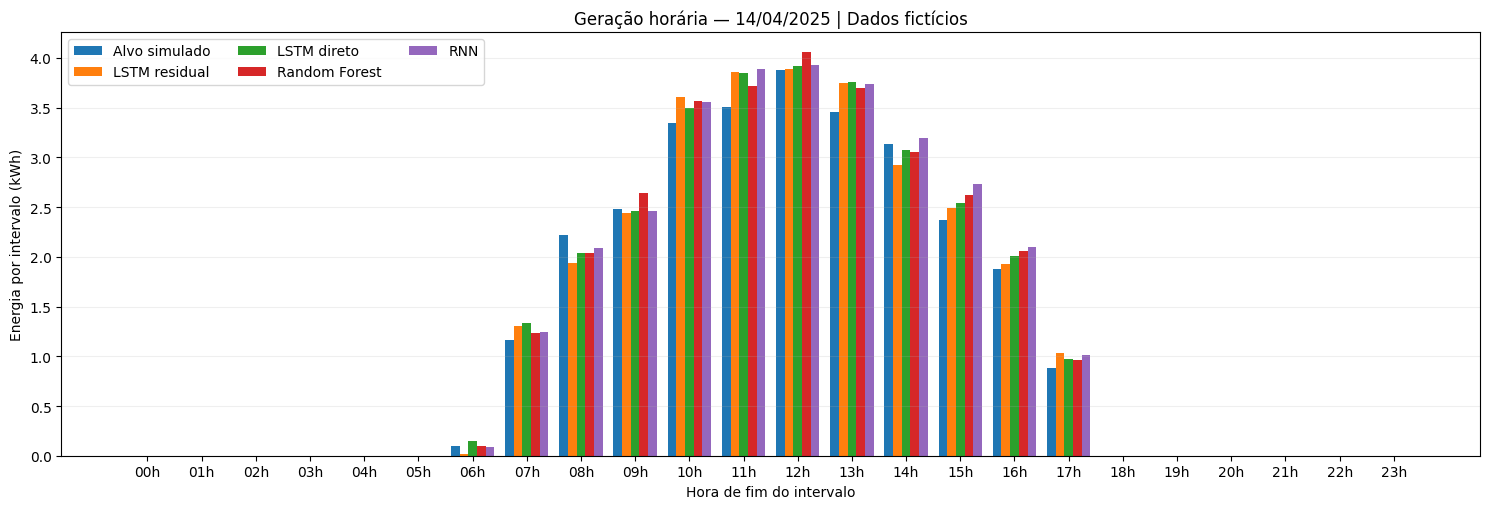

,alvo_kwh,LSTM_residual_fisico_42,LSTM_Huber_42,RandomForest_42,RNN_42
data_hora,,,,,
2025-04-14 00:00:00,0.000,0.000,0.000,0.000,0.000
2025-04-14 01:00:00,0.000,0.000,0.000,0.000,0.000
2025-04-14 02:00:00,0.000,0.000,0.000,0.000,0.000
2025-04-14 03:00:00,0.000,0.000,0.000,0.000,0.000
2025-04-14 04:00:00,0.000,0.000,0.000,0.000,0.000
2025-04-14 05:00:00,0.000,0.000,0.000,0.000,0.000
2025-04-14 06:00:00,0.096,0.021,0.153,0.097,0.089
2025-04-14 07:00:00,1.161,1.300,1.336,1.234,1.243
2025-04-14 08:00:00,2.223,1.939,2.038,2.037,2.090


In [ ]:
previsoes = pd.read_csv(SAIDA/'previsoes.csv',parse_dates=['data_hora']).set_index('data_hora')
sizes = previsoes.groupby(previsoes.index.normalize()).size()
full = sizes[sizes==24]
if not full.empty:
    date = full.index[0]
    dia = previsoes.loc[date:date+pd.Timedelta(hours=23)]
    dia.to_csv(SAIDA/'dados_24h.csv')
    seed=SEMENTES[0]
    cols=['alvo_kwh',f'LSTM_residual_fisico_{seed}',f'LSTM_Huber_{seed}',f'RandomForest_{seed}',f'RNN_{seed}']
    names=['Alvo simulado' if MODO=='demo' else 'Alvo CSV','LSTM residual','LSTM direto','Random Forest','RNN']
    x=np.arange(24); w=.16
    fig,ax=plt.subplots(figsize=(15,5.2))
    for i,(col,name) in enumerate(zip(cols,names)):
        ax.bar(x+(i-2)*w,dia[col],w,label=name)
    ax.set_xticks(x,[f'{h:02d}h' for h in dia.index.hour])
    ax.set(ylabel='Energia por intervalo (kWh)',xlabel='Hora de fim do intervalo',title=f'Geração horária — {date:%d/%m/%Y} | {natureza}')
    ax.grid(axis='y',alpha=.2); ax.legend(ncol=3,loc='upper left'); fig.tight_layout()
    fig.savefig(SAIDA/'comparacao_24h.png',dpi=170); plt.show()
    display(dia[cols].round(3))
else:
    print('Não há dia completo no teste.')

## 11. Gráficos de erros
Menor MAE e WAPE indicam menor erro nessas métricas.

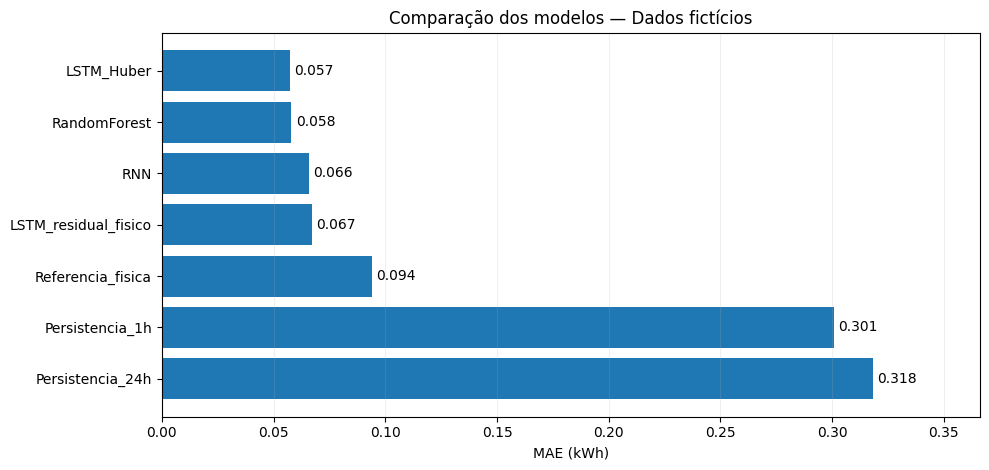

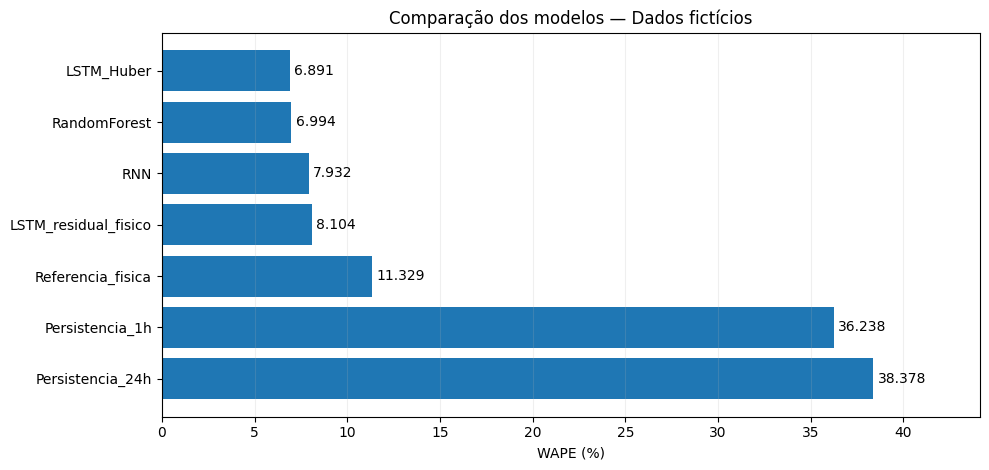

In [ ]:
for coluna,unidade,arquivo in [('MAE_kWh','MAE (kWh)','comparacao_erros.png'),('WAPE_pct','WAPE (%)','comparacao_wape.png')]:
    ordem=resumo.sort_values(coluna)
    fig,ax=plt.subplots(figsize=(10,4.8))
    bars=ax.barh(ordem.index,ordem[coluna]); ax.invert_yaxis(); ax.bar_label(bars,fmt='%.3f',padding=3); ax.margins(x=.15)
    ax.set(xlabel=unidade,title=f'Comparação dos modelos — {natureza}'); ax.grid(axis='x',alpha=.2); fig.tight_layout()
    fig.savefig(SAIDA/arquivo,dpi=170); plt.show()

## 12. Inferência de uma hora
Usa o LSTM residual salvo com 24 horas anteriores e clima da hora-alvo. O exemplo oculta o alvo. Não é uma previsão do dia inteiro feita de uma vez. Carregue somente modelos e arquivos joblib confiáveis.

In [ ]:
def predict(d,a,out):
    import joblib
    seed=a.seeds[0]; s=joblib.load(out/f'escalas_{seed}.joblib'); ph=reference(d,a.cfg); idx=d.index; mid=idx-pd.Timedelta(minutes=30); h=mid.hour+mid.minute/60; yr=mid.dayofyear
    cal=np.column_stack([np.sin(2*np.pi*h/24),np.cos(2*np.pi*h/24),np.sin(2*np.pi*yr/365.25),np.cos(2*np.pi*yr/365.25),sun_elev(mid,a.lat,a.lon)])
    X=np.column_stack([d.energia_kwh,d[METEO]])[-25:-1]; Z=np.column_stack([d[METEO],cal,ph[['poa_wm2','temp_celula_c','referencia_kwh']]])[-1:]; base=ph.referencia_kwh.iloc[-1]
    if len(X)!=24 or not np.isfinite(X).all() or not np.isfinite(Z).all(): raise ValueError('24 horas medidas completas + linha-alvo com previsão meteorológica obrigatórias')
    xn=s['sx'].transform(X)[None].astype('float32'); zn=np.column_stack([s['sz'].transform(Z),[base/s['escala_base']]]).astype('float32'); model=Net(s['h'],s['z'],'LSTM'); model.load_state_dict(torch.load(out/f'lstm_{seed}.pt',map_location='cpu',weights_only=True)); model.eval()
    with torch.no_grad(): res=s['sy'].inverse_transform(model(torch.from_numpy(xn),torch.from_numpy(zn)).numpy())[0,0]
    print(idx[-1], 'energia prevista (kWh):',float(np.clip(base+res,0,a.capacidade_kw)) if ph.diurno.iloc[-1] else 0.)

In [ ]:
diurnas = previsoes[previsoes.alvo_kwh>0]
instante = (diurnas if not diurnas.empty else previsoes).index[0]
entrada = dados.loc[instante-pd.Timedelta(hours=24):instante].copy()
entrada.loc[instante,'energia_kwh']=np.nan
entrada.to_csv(SAIDA/'exemplo_previsao_25h.csv',index_label='data_hora')
predict(entrada,args,SAIDA)
print('Alvo de comparação:',previsoes.loc[instante,'alvo_kwh'],'kWh |',natureza)

2025-04-13 06:00:00 energia prevista (kWh): 0.03625488316394165
Alvo de comparação: 0.0656252407423935 kWh | Dados fictícios


## 13. Exportação e limitações
Os dados, métricas, gráficos, pesos e normalizadores ficam em `resultados_v3_notebook`. O modo padrão é sintético; a precisão real permanece desconhecida. Para validação real, obtenha medições e meteorologia da mesma instalação e horários. Referências: [PVWatts/Sandia](https://pvpmc.sandia.gov/modeling-guide/2-dc-module-iv/point-value-models/pvwatts/), [ONS](https://dados.ons.org.br/dataset/geracao-usina-2), [Open-Meteo](https://open-meteo.com/en/docs/previous-runs-api).

In [ ]:
import shutil
print('Resultados exportados:',shutil.make_archive(str(SAIDA),'zip',root_dir=SAIDA))

Resultados exportados: /content/resultados_v3_notebook.zip


In [ ]:
# Previsão operacional experimental — executar depois do treinamento da V3.
# Dependência adicional, se necessário: %pip install requests
import requests
import joblib
from pathlib import Path


def previsao_por_coordenadas(latitude, longitude, pasta, horas=24, csv_geracao=None, agora=None):
    if not (-90 <= latitude <= 90 and -180 <= longitude <= 180):
        raise ValueError('Coordenadas inválidas.')
    if not isinstance(horas, int) or not 1 <= horas <= 24:
        raise ValueError('Escolha de 1 a 24 horas.')
    pasta = Path(pasta)
    # A V3 salva somente os pesos do LSTM residual. Seleção por validação,
    # não pelo conjunto de teste. Não carregar arquivos de terceiros.
    val = pd.read_csv(pasta / 'validacao.csv')
    candidatos = val.loc[val.modelo.eq('LSTM_residual_fisico')].copy()
    candidatos['seed'] = pd.to_numeric(candidatos.seed, errors='coerce')
    candidatos = candidatos.dropna(subset=['seed', 'MAE_val_kWh'])
    candidatos = candidatos[candidatos.seed.map(lambda s: (pasta / f'lstm_{int(s)}.pt').is_file() and (pasta / f'escalas_{int(s)}.joblib').is_file())]
    if candidatos.empty:
        raise FileNotFoundError('Nenhum LSTM residual salvo. Execute o treinamento primeiro.')
    melhor = candidatos.sort_values('MAE_val_kWh').iloc[0]
    seed = int(melhor.seed)
    escalas = joblib.load(pasta / f'escalas_{seed}.joblib')
    modelo = Net(escalas['h'], escalas['z'], 'LSTM')
    modelo.load_state_dict(torch.load(pasta / f'lstm_{seed}.pt', map_location='cpu', weights_only=True))
    modelo.eval()
    cfg = json.loads((pasta / 'config_sistema.json').read_text(encoding='utf-8'))
    origem = (cfg['latitude'], cfg['longitude'])
    cfg.update(latitude=float(latitude), longitude=float(longitude))
    if origem != (latitude, longitude):
        print('AVISO: nova localização; a transferência do modelo não foi validada.')
    # A geometria solar da V3 usa UTC-3 fixo. Todos os horários abaixo
    # são exibidos no fuso de Pernambuco, inclusive para outras coordenadas.
    agora = pd.Timestamp.now(tz='America/Recife') if agora is None else pd.Timestamp(agora)
    agora = agora.tz_localize('America/Recife') if agora.tzinfo is None else agora.tz_convert('America/Recife')
    ultima = agora.tz_localize(None).floor('h')
    inicio = ultima - pd.Timedelta(hours=23)
    # Começa no primeiro intervalo que ainda não terminou. Se a hora atual
    # já começou, a primeira previsão inclui a parte transcorrida.
    fins = pd.date_range(ultima + pd.Timedelta(hours=1), periods=horas, freq='h')
    indice = pd.date_range(inicio, fins[-1], freq='h')
    resposta = requests.get('https://api.open-meteo.com/v1/forecast', params={
        'latitude': latitude, 'longitude': longitude, 'hourly': ','.join(METEO),
        'timezone': 'America/Recife', 'past_days': 2, 'forecast_days': 3,
        'temperature_unit': 'celsius', 'wind_speed_unit': 'kmh', 'precipitation_unit': 'mm',
    }, timeout=45)
    resposta.raise_for_status()
    hourly = resposta.json()['hourly']
    clima = pd.DataFrame(hourly).set_index('time')
    clima.index = pd.to_datetime(clima.index)
    clima = clima[METEO].apply(pd.to_numeric, errors='coerce').reindex(indice)
    if not np.isfinite(clima.to_numpy()).all():
        raise ValueError('A API não retornou todas as variáveis para as horas necessárias.')
    fisica = reference(clima, cfg)
    clima['energia_kwh'] = np.nan
    historico_idx = indice[:24]
    if csv_geracao is None:
        # A coordenada fornece meteorologia, não a telemetria do inversor.
        clima.loc[historico_idx, 'energia_kwh'] = fisica.loc[historico_idx, 'referencia_kwh']
        origem_hist = 'estimativa física (não medida)'
    else:
        med = pd.read_csv(csv_geracao, parse_dates=['data_hora']).set_index('data_hora')
        if med.index.tz is not None:
            med.index = med.index.tz_convert('America/Recife').tz_localize(None)
        if med.index.has_duplicates:
            raise ValueError('CSV com horários duplicados.')
        med = pd.to_numeric(med.energia_kwh, errors='coerce').reindex(historico_idx)
        if not np.isfinite(med.to_numpy()).all() or (med < 0).any():
            raise ValueError('CSV deve conter 24 horas anteriores completas de geração AC em kWh, com horário de fim do intervalo.')
        clima.loc[historico_idx, 'energia_kwh'] = med
        origem_hist = 'geração medida informada por CSV'
    mid = indice - pd.Timedelta(minutes=30)
    h = mid.hour + mid.minute / 60
    yr = mid.dayofyear
    calendario = np.column_stack([np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24),
        np.sin(2*np.pi*yr/365.25), np.cos(2*np.pi*yr/365.25),
        sun_elev(mid, latitude, longitude)])
    Z = np.column_stack([clima[METEO], calendario,
                        fisica[['poa_wm2', 'temp_celula_c', 'referencia_kwh']]])
    for i in range(24, len(indice)):
        X = clima.iloc[i-24:i][['energia_kwh'] + METEO].to_numpy(float)
        base = float(fisica.referencia_kwh.iloc[i])
        xn = escalas['sx'].transform(X)[None].astype('float32')
        zn = np.column_stack([escalas['sz'].transform(Z[i:i+1]),
                              [base / escalas['escala_base']]]).astype('float32')
        with torch.no_grad():
            residual = escalas['sy'].inverse_transform(modelo(torch.from_numpy(xn), torch.from_numpy(zn)).numpy())[0, 0]
        p = float(np.clip(base + residual, 0, cfg['inversor_kw'])) if fisica.diurno.iloc[i] else 0.0
        if not np.isfinite(p):
            raise ValueError('Modelo gerou previsão não finita.')
        # Cada previsão alimenta a janela da próxima hora (recursão).
        clima.loc[indice[i], 'energia_kwh'] = p
    resultado = clima.loc[fins, METEO].copy()
    resultado['referencia_fisica_kwh'] = fisica.loc[fins, 'referencia_kwh']
    resultado['previsao_lstm_kwh'] = clima.loc[fins, 'energia_kwh']
    resultado.index.name = 'data_hora_fim_UTC-3'
    resultado.attrs.update(seed=seed, mae_validacao=float(melhor.MAE_val_kWh), origem_historico=origem_hist)
    print(f'LSTM residual salvo: semente {seed} | MAE de validação: {melhor.MAE_val_kWh:.4f} kWh')
    print(f'Histórico de geração: {origem_hist}; meteorologia: Open-Meteo (saída de modelos meteorológicos).')
    print('Previsão recursiva experimental; erro pode acumular. Sem garantia de precisão local.')
    print('Horários em UTC-3, fim do intervalo. A primeira hora pode estar em andamento.')
    print(f'Energia estimada nos {horas} intervalos: {resultado.previsao_lstm_kwh.sum():.3f} kWh')
    return resultado

LSTM residual salvo: semente 2026 | MAE de validação: 0.0626 kWh
Histórico de geração: estimativa física (não medida); meteorologia: Open-Meteo (saída de modelos meteorológicos).
Previsão recursiva experimental; erro pode acumular. Sem garantia de precisão local.
Horários em UTC-3, fim do intervalo. A primeira hora pode estar em andamento.
Energia estimada nos 24 intervalos: 25.181 kWh


,shortwave_radiation,direct_normal_irradiance,diffuse_radiation,temperature_2m,cloud_cover,precipitation,wind_speed_10m,relative_humidity_2m,referencia_fisica_kwh,previsao_lstm_kwh
data_hora_fim_UTC-3,,,,,,,,,,
2026-11-26 15:00:00,548.0,601.3,167.0,29.9,59,0.0,12.7,56,2.342,2.069
2026-11-26 16:00:00,311.0,398.4,140.0,29.3,40,0.0,11.7,58,1.339,1.183
2026-11-26 17:00:00,136.0,412.2,54.0,28.5,20,0.0,11.3,62,0.526,0.387
2026-11-26 18:00:00,6.0,31.4,4.0,28.2,11,0.0,10.3,63,0.019,0.000
2026-11-26 19:00:00,0.0,0.0,0.0,28.1,18,0.0,11.3,64,0.000,0.000
2026-11-26 20:00:00,0.0,0.0,0.0,28.0,14,0.0,12.5,65,0.000,0.000
2026-11-26 21:00:00,0.0,0.0,0.0,27.9,5,0.0,14.5,66,0.000,0.000
2026-11-26 22:00:00,0.0,0.0,0.0,27.6,17,0.0,15.4,67,0.000,0.000
2026-11-26 23:00:00,0.0,0.0,0.0,27.3,41,0.0,15.6,69,0.000,0.000


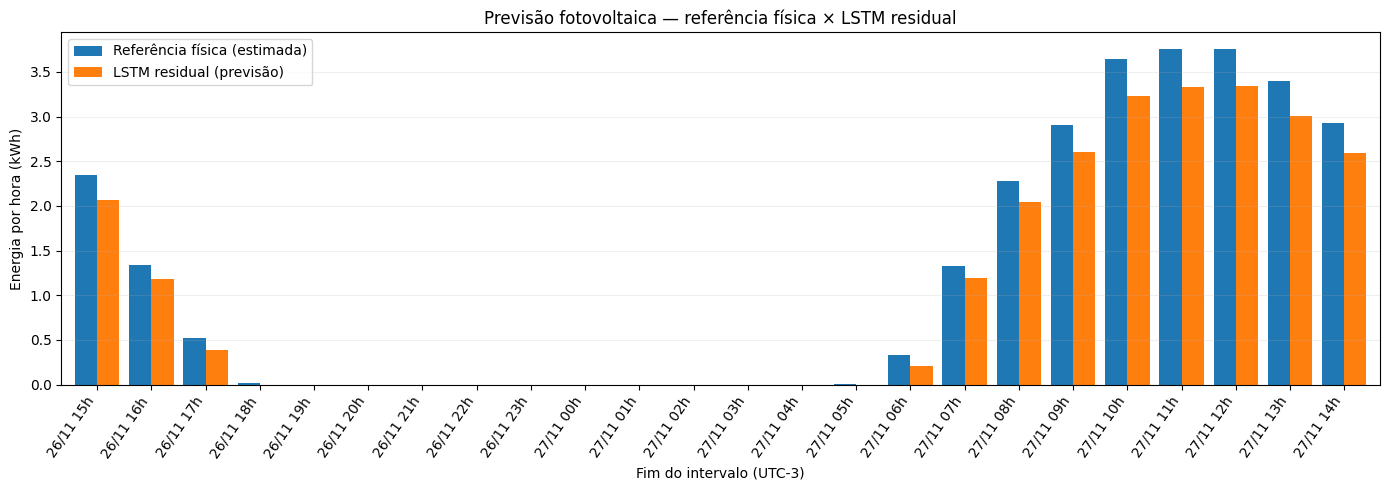

In [ ]:
LATITUDE = -8.05
LONGITUDE = -34.88

HORAS = 24
CSV_GERACAO = None  # Ex.: 'geracao_recente.csv' (data_hora, energia_kwh)
PASTA_MODELOS = SAIDA  # pasta com validacao.csv, config_sistema.json e pesos


previsao_local = previsao_por_coordenadas(LATITUDE, LONGITUDE, PASTA_MODELOS, HORAS, CSV_GERACAO)
display(previsao_local.round(3))

ax = previsao_local[['referencia_fisica_kwh', 'previsao_lstm_kwh']].plot.bar(figsize=(14, 5), width=.82)
ax.set_xticklabels(previsao_local.index.strftime('%d/%m %Hh'), rotation=55, ha='right')
ax.set(ylabel='Energia por hora (kWh)', xlabel='Fim do intervalo (UTC-3)', title='Previsão fotovoltaica — referência física × LSTM residual')
ax.legend(['Referência física (estimada)', 'LSTM residual (previsão)'])
ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()
previsao_local.to_csv(Path(PASTA_MODELOS) / 'previsao_meteorologica_24h.csv')
